# Deep Hedging with Market Frictions — Phase II
**AMS 520: Machine Learning in Quantitative Finance (Fall 2026) · Hetvi Soni**

**Phase II scope (per syllabus):** exploratory data analysis (EDA) and first empirical results.

**What this notebook does**
1. Fixes the hedging problem precisely (which option, how often we trade, what costs).
2. EDA: the stylized facts of real S&P 500 returns that break Black–Scholes.
3. Calibrates two market simulators (GBM and Heston) on the **training period only** (2005–2018).
4. Builds the deep hedging model in PyTorch and the Black–Scholes delta benchmark.
5. Experiments:
   * **Sanity check:** with no trading costs, the network should reproduce the Black–Scholes delta.
   * **RQ1:** with transaction costs, does deep hedging beat Black–Scholes delta? (GBM and Heston markets)
   * **RQ2 preview:** do the trained hedgers still work on **real SPY history from 2019 onward**?

Input: `data/processed/market_daily_clean.csv` from the Phase I notebook.

## 0. The option we hedge (design decision)

| Choice | Value | Why |
|---|---|---|
| Option type | **European call** | Payoff depends only on the final price, so hedging quality is measured cleanly. This is the standard setting of the deep hedging literature (Buehler et al., 2019), which makes our results comparable. |
| Position | **We sold the option** (short call) | The bank's situation: it must hedge the risk it took on. |
| Strike | At-the-money, K = S₀ = 100 | Hardest case to hedge: delta changes fastest near the money. |
| Maturity | 21 trading days (≈ 1 month) | Matches the real hedging windows built in Phase I. |
| Rebalancing | Daily | Realistic for a hedging desk; matches daily data. |
| Hedging instrument | The underlying (SPY) | Single-instrument hedge, as in the benchmark. |
| Transaction cost | Proportional: c × |trade| × price, with c ∈ {0, 0.1%, 0.5%} | 0 = sanity check; 0.1% and 0.5% = moderate and high frictions. |

**Why European and not American?**
An American option can be exercised early, so the hedger must also handle an *optimal stopping* decision, which mixes two
problems (when to exercise, how to hedge) and makes it impossible to tell which one caused a hedging error.
For a call on a stock or ETF, early exercise is rarely optimal anyway (only just before a dividend), so an American call
behaves almost like a European one. S&P 500 index options (SPX) — the most liquid options on this index — are European.
**American options are a natural Phase III extension** (e.g., an American put, where early exercise really matters).

**How results are measured.** For each scenario we compute the hedger's **loss**:

$$\text{Loss} = \underbrace{\max(S_T-K,0)}_{\text{payoff we owe}} \;-\; \underbrace{\sum_k \delta_k (S_{k+1}-S_k)}_{\text{trading gains}} \;+\; \underbrace{\sum_k c\,S_k\,|\delta_k-\delta_{k-1}|}_{\text{transaction costs}}$$

The premium received for the option is a constant, so it is left out. We report the mean, standard deviation and
**CVaR 95%** of the loss (average of the worst 5% of scenarios). The CVaR is also the **price the bank would need to charge**
to be comfortable selling the option, so lower CVaR = better hedge = cheaper option for the client.

## 1. Setup

In [ ]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

SEED = 520
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.11.0+cu130 | device: cuda


In [ ]:
# ---- Problem configuration (single source of truth) ----
TRADING_DAYS = 252
N_STEPS = 21                 # rebalancing dates = trading days to maturity
DT = 1 / TRADING_DAYS
T = N_STEPS * DT
S0, K = 100.0, 100.0         # at-the-money European call
ALPHA = 0.95                 # CVaR level: average of worst 5% of outcomes
COSTS = [0.0, 0.001, 0.005]  # proportional transaction costs: 0, 0.1%, 0.5%
TRAIN_END = "2018-12-31"     # calibrate on data up to here; test on 2019+

# ---- Training configuration ----
ITERS = 800                  # gradient steps per model (raise to 1500+ for final results)
BATCH = 8192                 # simulated paths per step
LR = 5e-3
N_EVAL = 100_000             # fresh simulated paths for evaluation

## 2. Load the Phase I data

In [ ]:
PATH = "data/processed/market_daily_clean.csv"
if not os.path.exists(PATH):
    raise FileNotFoundError(
        "Upload the Phase I output (data/processed/market_daily_clean.csv) or run the Phase I notebook first. "
        "In Colab: click the folder icon on the left, create data/processed/, and upload the file there.")

df = pd.read_csv(PATH, index_col="date", parse_dates=True)
train = df.loc[:TRAIN_END]
test = df.loc[pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1):]
print(f"Full sample: {df.index.min().date()} – {df.index.max().date()} ({len(df):,} days)")
print(f"Train/calibration: {len(train):,} days | Test: {len(test):,} days")
df.head()

Full sample: 2005-01-04 – 2026-09-29 (5,468 days)
Train/calibration: 3,522 days | Test: 1,946 days


,spy,volume,vix,r,log_ret,realized_vol_21d,robust_z,extreme_flag
date,,,,,,,,
2005-01-04,79.9841,69167600,0.1398,0.0234,-0.0123,NaN,-1.7907,False
2005-01-05,79.4321,65667300,0.1409,0.0233,-0.0069,NaN,-1.0510,False
2005-01-06,79.8360,47814700,0.1358,0.0231,0.0051,NaN,0.6013,False
2005-01-07,79.7216,55847700,0.1349,0.0232,-0.0014,NaN,-0.2947,False
2005-01-10,80.0985,56563300,0.1323,0.0237,0.0047,NaN,0.5524,False


## 3. Exploratory data analysis: how real returns break Black–Scholes

Black–Scholes assumes returns are **normal**, **independent over time**, with **constant volatility**.
We check each assumption against the data.

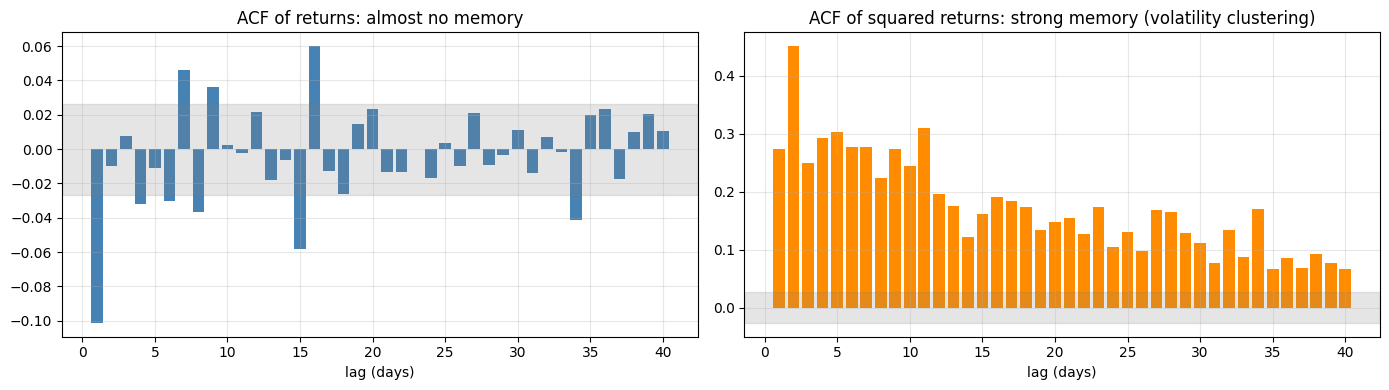

Mean ACF lags 1-10: returns -0.013 | squared returns +0.286


In [ ]:
def acf(x, max_lag=40):
    x = np.asarray(x) - np.mean(x)
    v = np.dot(x, x)
    return np.array([np.dot(x[:-k], x[k:]) / v for k in range(1, max_lag + 1)])

r = df["log_ret"].values
lags = np.arange(1, 41)
band = 1.96 / np.sqrt(len(r))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(lags, acf(r), color="steelblue"); ax[0].axhspan(-band, band, color="gray", alpha=0.2)
ax[0].set_title("ACF of returns: almost no memory"); ax[0].set_xlabel("lag (days)")
ax[1].bar(lags, acf(r**2), color="darkorange"); ax[1].axhspan(-band, band, color="gray", alpha=0.2)
ax[1].set_title("ACF of squared returns: strong memory (volatility clustering)"); ax[1].set_xlabel("lag (days)")
plt.tight_layout(); plt.savefig("figures/p2_01_volatility_clustering.png", dpi=150); plt.show()

print(f"Mean ACF lags 1-10: returns {acf(r)[:10].mean():+.3f} | squared returns {acf(r**2)[:10].mean():+.3f}")

**Volatility clustering.** Returns themselves are nearly unpredictable, but *squared* returns are strongly correlated for weeks:
calm days follow calm days and wild days follow wild days. Volatility is **not constant** — it moves in regimes.
This is exactly what the Heston model adds and GBM ignores.

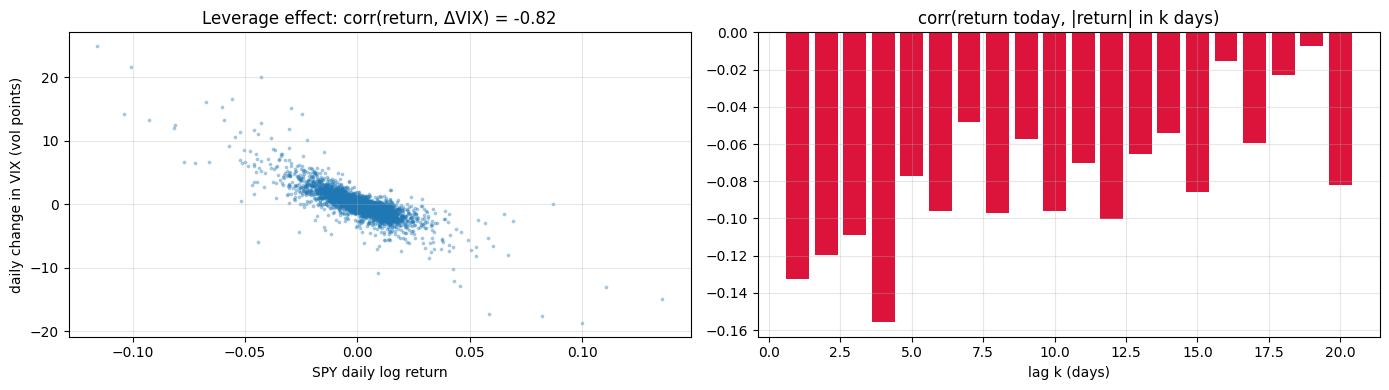

In [ ]:
dvix = df["vix"].diff()
corr_lev = np.corrcoef(df["log_ret"].values[1:], dvix.values[1:])[0, 1]

# Lagged leverage: does today's return predict future volatility?
abs_r = np.abs(r)
lev_lags = [np.corrcoef(r[:-k], abs_r[k:])[0, 1] for k in range(1, 21)]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(df["log_ret"], dvix * 100, s=3, alpha=0.3)
ax[0].set_xlabel("SPY daily log return"); ax[0].set_ylabel("daily change in VIX (vol points)")
ax[0].set_title(f"Leverage effect: corr(return, ΔVIX) = {corr_lev:.2f}")
ax[1].bar(range(1, 21), lev_lags, color="crimson")
ax[1].set_xlabel("lag k (days)"); ax[1].set_title("corr(return today, |return| in k days)")
plt.tight_layout(); plt.savefig("figures/p2_02_leverage_effect.png", dpi=150); plt.show()

**Leverage effect.** When the market falls, volatility jumps (strongly negative correlation between returns and VIX changes),
and negative returns are followed by larger moves later. For a hedger this is the worst combination: losses arrive together
with higher volatility. In Heston this is captured by a **negative correlation ρ** between price and variance shocks.

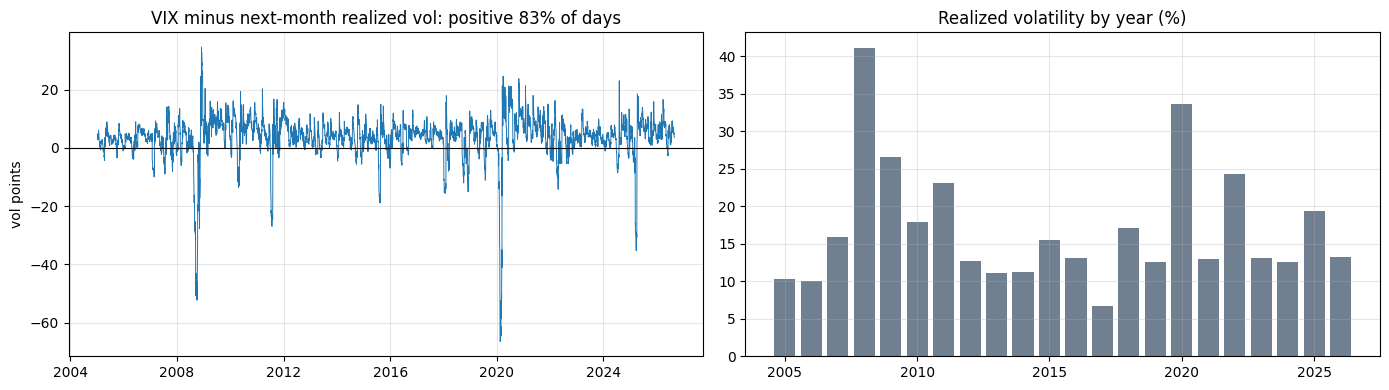

Average VIX 19.1% vs average realized vol 18.9%
Calmest year 2017 (6.7%), wildest year 2008 (41.2%)


In [ ]:
fwd_rv = df["log_ret"].rolling(N_STEPS).std().shift(-N_STEPS) * np.sqrt(TRADING_DAYS)  # vol realized over next month
vrp = (df["vix"] - fwd_rv).dropna()
yearly_vol = df["log_ret"].groupby(df.index.year).std() * np.sqrt(TRADING_DAYS)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(vrp.index, vrp * 100, lw=0.7); ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title(f"VIX minus next-month realized vol: positive {(vrp > 0).mean():.0%} of days")
ax[0].set_ylabel("vol points")
ax[1].bar(yearly_vol.index, yearly_vol * 100, color="slategray")
ax[1].set_title("Realized volatility by year (%)")
plt.tight_layout(); plt.savefig("figures/p2_03_vol_premium_and_regimes.png", dpi=150); plt.show()

print(f"Average VIX {df['vix'].mean():.1%} vs average realized vol {df['log_ret'].std()*np.sqrt(252):.1%}")
print(f"Calmest year {yearly_vol.idxmin()} ({yearly_vol.min():.1%}), wildest year {yearly_vol.idxmax()} ({yearly_vol.max():.1%})")

**Volatility risk premium and regimes.** The VIX (what options *imply*) is usually above the volatility that actually happens,
because investors pay extra for protection. Volatility also differs hugely across years. Implication for the project:
a hedger calibrated to one constant volatility (Black–Scholes, GBM) will be wrong most of the time, and implied volatility
must be **rescaled** before being used as a forecast of real volatility (done in the calibration below).

**EDA summary — every Black–Scholes assumption fails:** returns are fat-tailed (Phase I: excess kurtosis ≈ 15),
volatility clusters, volatility is negatively correlated with returns, and implied volatility is biased upward.

## 4. Calibrating the simulators (training period 2005–2018 only)

Deep hedging learns from simulated paths, so the simulators must resemble the real market.

**GBM (Black–Scholes world):** constant volatility σ = realized volatility of the training period.

**Heston (stochastic volatility):**
$dS_t = \sqrt{v_t}\,S_t\,dW^S_t, \qquad dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW^v_t, \qquad \text{corr}(dW^S, dW^v) = \rho$

* κ = speed at which volatility returns to normal, θ = long-run variance, ξ = volatility of volatility, ρ = leverage correlation.
* We use the daily **VIX², rescaled to match realized variance**, as an observable proxy for the variance $v_t$, and estimate
  κ, θ, ξ by regression on its daily changes (a discretized Euler scheme); ρ is the correlation of price and variance shocks.
* Drift is set to zero in both simulators, so the hedger learns to **hedge**, not to bet on the market going up.

In [ ]:
# ---- GBM ----
sigma_gbm = train["log_ret"].std() * np.sqrt(TRADING_DAYS)

# ---- Heston: variance proxy = rescaled VIX^2 ----
vix_scale = (train["log_ret"]**2).mean() / (train["vix"]**2 * DT).mean()   # implied -> realized variance
v = (train["vix"]**2 * vix_scale).values
sv = np.sqrt(v[:-1])
y = (v[1:] - v[:-1]) / sv                          # (v_{t+1} - v_t) / sqrt(v_t)
X = np.column_stack([1 / sv, sv])                  # y = kappa*theta*dt / sqrt(v) - kappa*dt * sqrt(v) + noise
b, *_ = np.linalg.lstsq(X, y, rcond=None)
kappa = -b[1] / DT
theta = b[0] / (kappa * DT)
resid_v = y - X @ b
xi = resid_v.std() / np.sqrt(DT)
eps_s = train["log_ret"].values[1:] / np.sqrt(v[:-1] * DT)   # standardized return shocks
rho = np.corrcoef(eps_s, resid_v)[0, 1]

if not (0 < kappa < 0.5 / DT):                      # guard against degenerate estimates
    print(f"Warning: kappa estimate {kappa:.2f} out of range, clipping."); kappa = float(np.clip(kappa, 0.5, 0.5 / DT))

calib = pd.Series({
    "GBM sigma (annual)": sigma_gbm,
    "VIX^2 -> realized variance scale": vix_scale,
    "Heston kappa (mean reversion speed)": kappa,
    "Heston theta (long-run variance)": theta,
    "Heston sqrt(theta) (long-run vol)": np.sqrt(theta),
    "Heston xi (vol of vol)": xi,
    "Heston rho (leverage)": rho,
    "Feller ratio 2*kappa*theta/xi^2 (>1 = variance stays positive)": 2 * kappa * theta / xi**2,
    "Half-life of a vol shock (days)": np.log(2) / kappa * TRADING_DAYS,
}, name="estimate")
calib.to_csv("results/calibration.csv")
V0_POOL = v                                          # starting variances drawn from the training history
calib.to_frame()

,estimate
GBM sigma (annual),0.1868
VIX^2 -> realized variance scale,0.8140
Heston kappa (mean reversion speed),3.4703
Heston theta (long-run variance),0.0357
Heston sqrt(theta) (long-run vol),0.1888
Heston xi (vol of vol),0.5460
Heston rho (leverage),-0.7387
Feller ratio 2*kappa*theta/xi^2 (>1 = variance stays positive),0.8303
Half-life of a vol shock (days),50.3332


**Reading the calibration.** ρ should be clearly negative (the leverage effect from the EDA). The half-life says how many days
a volatility shock takes to fade by half. A Feller ratio below 1 is typical for equity data and means variance can touch zero;
the simulator handles this with the standard *full truncation* scheme.
Each Heston path starts from a variance drawn from the 2005–2018 history, so the hedger sees calm and crisis regimes.

## 5. Simulators and the Black–Scholes benchmark

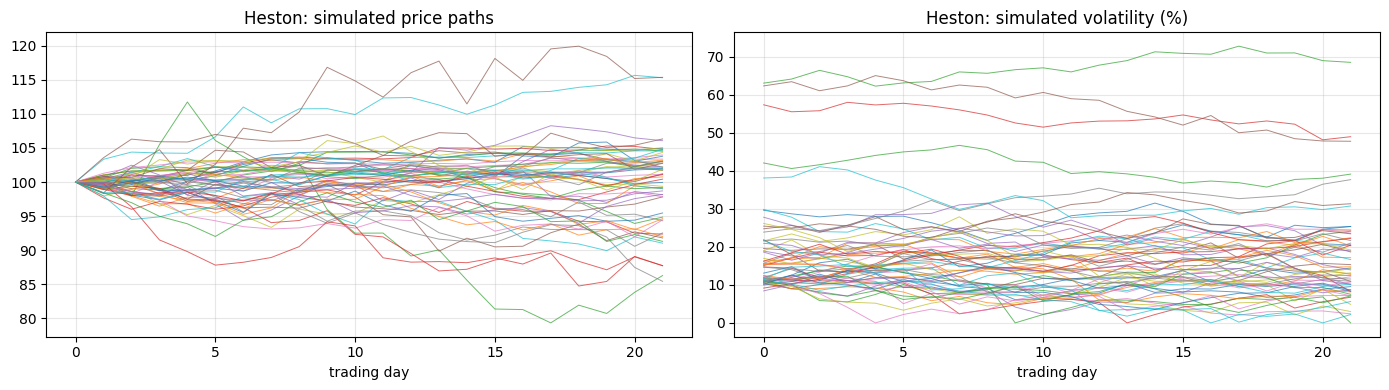

Black-Scholes price of the 1-month ATM call (GBM vol 18.7%): 2.151


In [ ]:
def simulate_gbm(n, sigma=None, seed=None):
    sigma = sigma_gbm if sigma is None else sigma
    g = np.random.default_rng(seed)
    z = g.standard_normal((n, N_STEPS))
    log_inc = -0.5 * sigma**2 * DT + sigma * np.sqrt(DT) * z
    S = S0 * np.exp(np.concatenate([np.zeros((n, 1)), np.cumsum(log_inc, axis=1)], axis=1))
    V = np.full_like(S, sigma**2)
    return S, V

def simulate_heston(n, seed=None):
    g = np.random.default_rng(seed)
    S = np.empty((n, N_STEPS + 1)); V = np.empty((n, N_STEPS + 1))
    S[:, 0] = S0
    V[:, 0] = g.choice(V0_POOL, size=n)
    for k in range(N_STEPS):
        z1 = g.standard_normal(n)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * g.standard_normal(n)
        vp = np.maximum(V[:, k], 0.0)                                   # full truncation
        S[:, k + 1] = S[:, k] * np.exp(-0.5 * vp * DT + np.sqrt(vp * DT) * z1)
        V[:, k + 1] = np.maximum(V[:, k] + kappa * (theta - vp) * DT + xi * np.sqrt(vp * DT) * z2, 1e-8)
    return S, V

def bs_call_price(S, tau, sigma):
    tau = np.maximum(tau, 1e-10)
    d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return S * norm.cdf(d1) - K * norm.cdf(d1 - sigma * np.sqrt(tau))

def bs_delta(S, tau, sigma):
    tau = np.maximum(tau, 1e-10)
    d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d1)

def hedge_bs(S, V, c):
    # Black-Scholes delta hedge, using the current volatility sqrt(V) at each date
    n = S.shape[0]
    pos = np.zeros(n); gains = np.zeros(n); cost = np.zeros(n); turnover = np.zeros(n)
    deltas = np.empty((n, N_STEPS))
    for k in range(N_STEPS):
        new = bs_delta(S[:, k], (N_STEPS - k) * DT, np.sqrt(V[:, k]))
        trade = np.abs(new - pos)
        cost += c * S[:, k] * trade; turnover += trade
        gains += new * (S[:, k + 1] - S[:, k]); pos = new; deltas[:, k] = new
    loss = np.maximum(S[:, -1] - K, 0) - gains + cost
    return {"loss": loss, "cost": cost, "turnover": turnover, "deltas": deltas}

S_demo, V_demo = simulate_heston(200, seed=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(S_demo[:60].T, lw=0.7, alpha=0.7); ax[0].set_title("Heston: simulated price paths")
ax[1].plot(np.sqrt(V_demo[:60].T) * 100, lw=0.7, alpha=0.7); ax[1].set_title("Heston: simulated volatility (%)")
for a in ax: a.set_xlabel("trading day")
plt.tight_layout(); plt.savefig("figures/p2_04_heston_paths.png", dpi=150); plt.show()
print(f"Black-Scholes price of the 1-month ATM call (GBM vol {sigma_gbm:.1%}): {bs_call_price(S0, T, sigma_gbm):.3f}")

## 6. The deep hedging model

At every trading day $k$ the **policy network** sees the current market state and outputs how many shares to hold, $\delta_k$:

| Input | Meaning | Why it is needed |
|---|---|---|
| $\log(S_k/K)\,/\,(\sigma_k\sqrt{\tau_k})$ | How far in/out of the money, in standard deviations | Core driver of the hedge |
| $\tau_k / T$ | Fraction of time left to maturity | Hedge changes as maturity nears |
| $\sigma_k / 0.2$ | Current volatility | Lets the hedge adapt to the regime (constant under GBM) |
| $\delta_{k-1}$ | **Position already held** | With costs, the best trade depends on where you are now — this is what lets the network learn a no-trade band |

Architecture: one network shared across all dates (time is an input), 3 hidden layers × 32 units, ReLU, and a sigmoid output
so positions stay in [0, 1] shares (the range of a call's delta).

**Training objective:** minimize CVaR 95% of the loss with the Rockafellar–Uryasev formula
$\text{CVaR}_\alpha(L) = \min_w \; w + \frac{1}{1-\alpha}\,\mathbb{E}[(L - w)^+]$, where $w$ is learned together with the network
(at the optimum, $w$ is the 95% Value-at-Risk). Every step draws a **fresh batch of simulated paths**, so the network cannot memorize data.

In [ ]:
class HedgePolicy(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1))
    def forward(self, x):
        return torch.sigmoid(self.net(x)).squeeze(-1)

def features(S_k, V_k, tau, prev):
    vol = torch.sqrt(V_k)
    return torch.stack([torch.log(S_k / K) / (vol * np.sqrt(tau)),
                        torch.full_like(S_k, tau / T), vol / 0.2, prev], dim=1)

def hedge_dh(policy, S, V, c):
    # Run the network along every path; S and V are torch tensors (n, N_STEPS+1)
    n = S.shape[0]
    pos = torch.zeros(n, device=S.device); gains = torch.zeros_like(pos)
    cost = torch.zeros_like(pos); turnover = torch.zeros_like(pos); deltas = []
    for k in range(N_STEPS):
        new = policy(features(S[:, k], V[:, k], (N_STEPS - k) * DT, pos))
        trade = torch.abs(new - pos)
        cost = cost + c * S[:, k] * trade; turnover = turnover + trade
        gains = gains + new * (S[:, k + 1] - S[:, k]); pos = new; deltas.append(new)
    loss = torch.relu(S[:, -1] - K) - gains + cost
    return {"loss": loss, "cost": cost, "turnover": turnover, "deltas": torch.stack(deltas, 1)}

def to_t(a):
    return torch.tensor(a, dtype=torch.float32, device=DEVICE)

def train_policy(simulator, c, iters=ITERS, batch=BATCH, lr=LR, label="", seed=SEED, policy_cls=None):
    torch.manual_seed(seed)
    policy = (policy_cls or HedgePolicy)().to(DEVICE)
    w = nn.Parameter(torch.tensor(2.0, device=DEVICE))            # learned VaR level
    opt = torch.optim.Adam(list(policy.parameters()) + [w], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters, eta_min=lr / 20)
    history, t0 = [], time.time()
    for it in range(iters):
        S, V = simulator(batch, seed=seed * 100_000 + it)
        out = hedge_dh(policy, to_t(S), to_t(V), c)
        objective = w + torch.relu(out["loss"] - w).mean() / (1 - ALPHA)
        opt.zero_grad(); objective.backward(); opt.step(); sched.step()
        history.append(objective.item())
    print(f"{label:<22} trained in {time.time() - t0:5.1f}s | final CVaR objective {np.mean(history[-50:]):.3f}")
    return policy, history

def metrics(res, name):
    L = np.asarray(res["loss"])
    q = np.quantile(L, ALPHA)
    return {"strategy": name, "mean loss": L.mean(), "std loss": L.std(), "VaR 95%": q,
            "CVaR 95%": L[L >= q].mean(), "mean cost": np.mean(res["cost"]), "mean turnover": np.mean(res["turnover"])}

def evaluate(policy, S, V, c):
    with torch.no_grad():
        out = hedge_dh(policy, to_t(S), to_t(V), c)
    return {k: v.cpu().numpy() for k, v in out.items()}

## 7. Train all models

Six networks: {GBM, Heston} × {0%, 0.1%, 0.5%} costs. Each is trained only on simulated paths from its own simulator.
On a Colab CPU this takes about 1 minute per model; with a GPU (Runtime → Change runtime type → T4 GPU) it is faster.

GBM, cost 0.0%         trained in  27.1s | final CVaR objective 2.983
GBM, cost 0.1%         trained in  26.1s | final CVaR objective 3.185
GBM, cost 0.5%         trained in  26.1s | final CVaR objective 4.004
Heston, cost 0.0%      trained in  33.1s | final CVaR objective 5.093
Heston, cost 0.1%      trained in  33.3s | final CVaR objective 5.372
Heston, cost 0.5%      trained in  33.4s | final CVaR objective 6.324


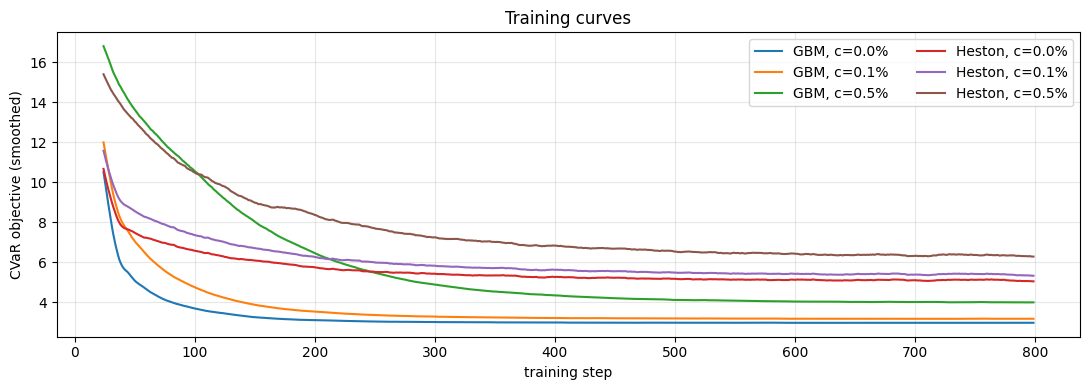

In [ ]:
SIMULATORS = {"GBM": simulate_gbm, "Heston": simulate_heston}
policies, histories = {}, {}
for model_name, sim in SIMULATORS.items():
    for c in COSTS:
        key = (model_name, c)
        policies[key], histories[key] = train_policy(sim, c, label=f"{model_name}, cost {c:.1%}")
        torch.save(policies[key].state_dict(), f"results/policy_{model_name}_{c}.pt")

fig, ax = plt.subplots(figsize=(11, 4))
for key, h in histories.items():
    ax.plot(pd.Series(h).rolling(25).mean(), label=f"{key[0]}, c={key[1]:.1%}")
ax.set_xlabel("training step"); ax.set_ylabel("CVaR objective (smoothed)"); ax.set_title("Training curves")
ax.legend(ncol=2); plt.tight_layout(); plt.savefig("figures/p2_05_training_curves.png", dpi=150); plt.show()

## 8. Sanity check: without costs, the network should rediscover Black–Scholes

In a GBM market with zero costs, theory says the Black–Scholes delta is (close to) optimal. If our pipeline is correct,
the network — which was never told the formula — should produce nearly the same hedge.

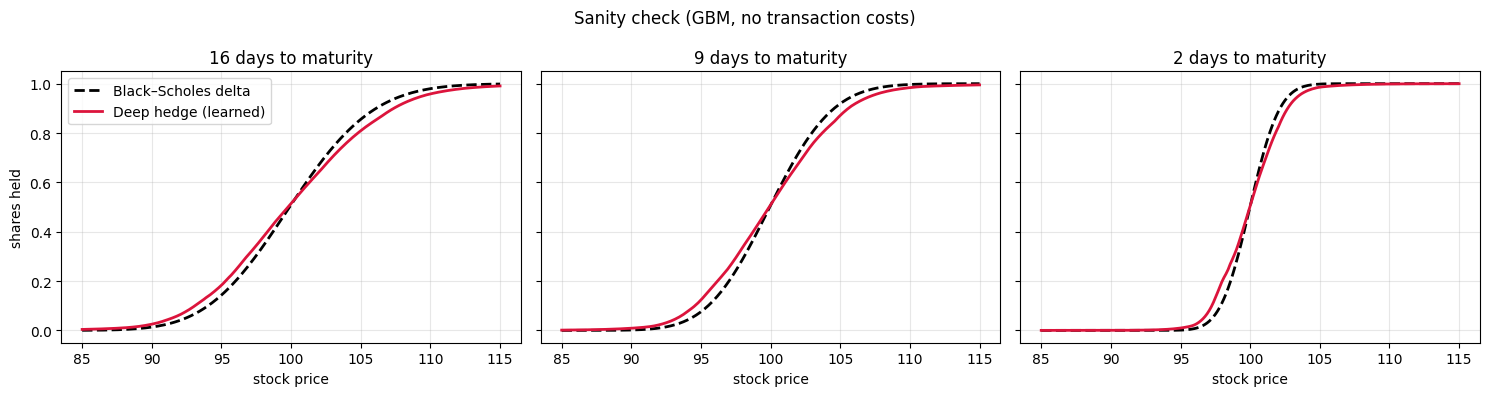

Average |deep hedge - BS delta| along simulated paths: 0.0279 shares (median 0.0274)
Mean hedging loss: deep hedge 2.150 vs BS 2.150 (BS option price 2.151)


In [ ]:
pol0 = policies[("GBM", 0.0)]
S_grid = np.linspace(85, 115, 200)
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, k in zip(ax, [5, 12, 19]):
    tau = (N_STEPS - k) * DT
    bs = bs_delta(S_grid, tau, sigma_gbm)
    with torch.no_grad():
        x = features(to_t(S_grid), to_t(np.full_like(S_grid, sigma_gbm**2)), tau, to_t(bs))
        nn_d = pol0(x).cpu().numpy()
    a.plot(S_grid, bs, "k--", lw=2, label="Black–Scholes delta")
    a.plot(S_grid, nn_d, color="crimson", lw=2, label="Deep hedge (learned)")
    a.set_title(f"{N_STEPS - k} days to maturity"); a.set_xlabel("stock price")
ax[0].set_ylabel("shares held"); ax[0].legend()
plt.suptitle("Sanity check (GBM, no transaction costs)"); plt.tight_layout()
plt.savefig("figures/p2_06_sanity_check.png", dpi=150); plt.show()

S_ev, V_ev = simulate_gbm(N_EVAL, seed=2026)
dh0, bs0 = evaluate(pol0, S_ev, V_ev, 0.0), hedge_bs(S_ev, V_ev, 0.0)
gap = np.abs(dh0["deltas"] - bs0["deltas"])
print(f"Average |deep hedge - BS delta| along simulated paths: {gap.mean():.4f} shares (median {np.median(gap):.4f})")
print(f"Mean hedging loss: deep hedge {dh0['loss'].mean():.3f} vs BS {bs0['loss'].mean():.3f} "
      f"(BS option price {bs_call_price(S0, T, sigma_gbm):.3f})")

**Interpretation.** If the curves lie nearly on top of each other, the whole pipeline (simulator, P&L, loss, training) is correct.
Small differences are expected: we rebalance daily rather than continuously, and the network minimizes CVaR rather than variance,
so the theoretically optimal discrete hedge is not exactly the continuous-time formula. The mean loss of both hedges should be close
to the Black–Scholes price: the price is exactly the cost of replicating the option.

## 9. RQ1: deep hedging vs Black–Scholes delta under transaction costs

In [ ]:
rows, eval_store = [], {}
for model_name, sim in SIMULATORS.items():
    S_ev, V_ev = sim(N_EVAL, seed=2026)                         # same fresh test paths for both strategies
    for c in COSTS:
        bs_res = hedge_bs(S_ev, V_ev, c)
        dh_res = evaluate(policies[(model_name, c)], S_ev, V_ev, c)
        eval_store[(model_name, c)] = (bs_res, dh_res)
        for res, name in [(bs_res, "BS delta"), (dh_res, "Deep hedge")]:
            m = metrics(res, name); m.update({"market": model_name, "cost": c}); rows.append(m)

results = pd.DataFrame(rows).set_index(["market", "cost", "strategy"])
results.to_csv("results/rq1_simulated_results.csv")
results

mean loss  std loss  VaR 95%  CVaR 95%  mean cost  \
market cost   strategy                                                        
GBM    0.0000 BS delta       2.1500    0.4008   2.8156    3.0895     0.0000   
              Deep hedge     2.1502    0.4400   2.7960    2.9848     0.0000   
       0.0010 BS delta       2.3428    0.4137   3.0574    3.3492     0.1928   
              Deep hedge     2.3205    0.4512   2.9837    3.1782     0.1703   
       0.0050 BS delta       3.1140    0.5114   4.0725    4.4339     0.9640   
              Deep hedge     2.8381    0.5198   3.6239    3.8616     0.6881   
Heston 0.0000 BS delta       1.9269    1.0082   3.8179    5.0155     0.0000   
              Deep hedge     1.9272    1.0082   3.7483    4.9727     0.0000   
       0.0010 BS delta       2.1203    1.0117   4.0170    5.2145     0.1934   
              Deep hedge     2.0887    1.0163   3.8951    5.1718     0.1616   
       0.0050 BS delta       2.8939    1.0507   4.8418    6.0397     0.9670   
              Deep hedge     2.5508    1.1185   4.2796    5.8136     0.6220   

                          mean turnover  
market cost   strategy                   
GBM    0.0000 BS delta           1.9284  
              Deep hedge         1.8083  
       0.0010 BS delta           1.9284  
              Deep hedge         1.7035  
       0.0050 BS delta           1.9284  
              Deep hedge         1.3763  
Heston 0.0000 BS delta           1.9328  
              Deep hedge         1.7244  
       0.0010 BS delta           1.9328  
              Deep hedge         1.6129  
       0.0050 BS delta           1.9328  
              Deep hedge         1.2414

In [ ]:
summary = (results["CVaR 95%"].unstack("strategy")
           .assign(improvement=lambda d: 1 - d["Deep hedge"] / d["BS delta"]))
summary["improvement"] = summary["improvement"].map("{:.1%}".format)
print("CVaR 95% of hedging loss (lower is better) and deep hedging improvement:")
display(summary)

CVaR 95% of hedging loss (lower is better) and deep hedging improvement:


strategy       BS delta  Deep hedge improvement
market cost                                    
GBM    0.0000    3.0895      2.9848        3.4%
       0.0010    3.3492      3.1782        5.1%
       0.0050    4.4339      3.8616       12.9%
Heston 0.0000    5.0155      4.9727        0.9%
       0.0010    5.2145      5.1718        0.8%
       0.0050    6.0397      5.8136        3.7%

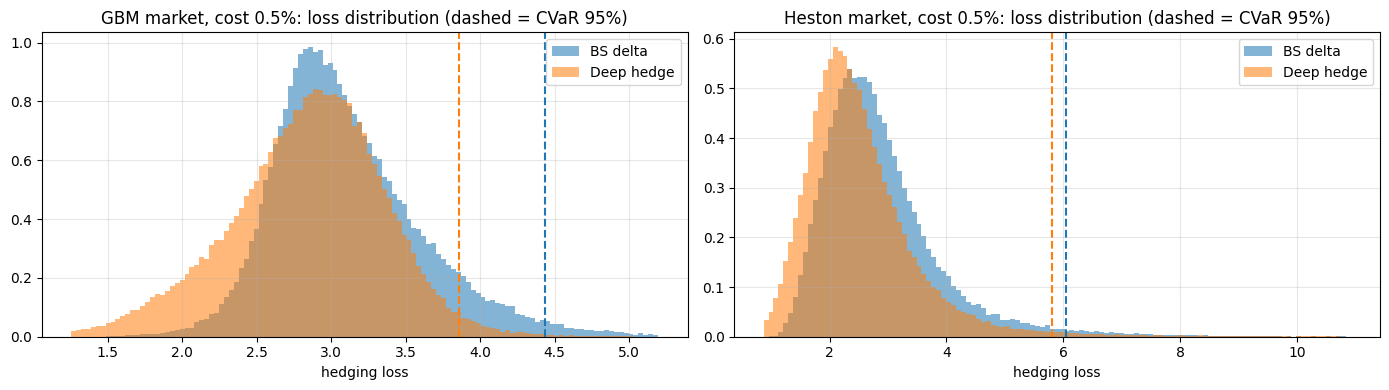

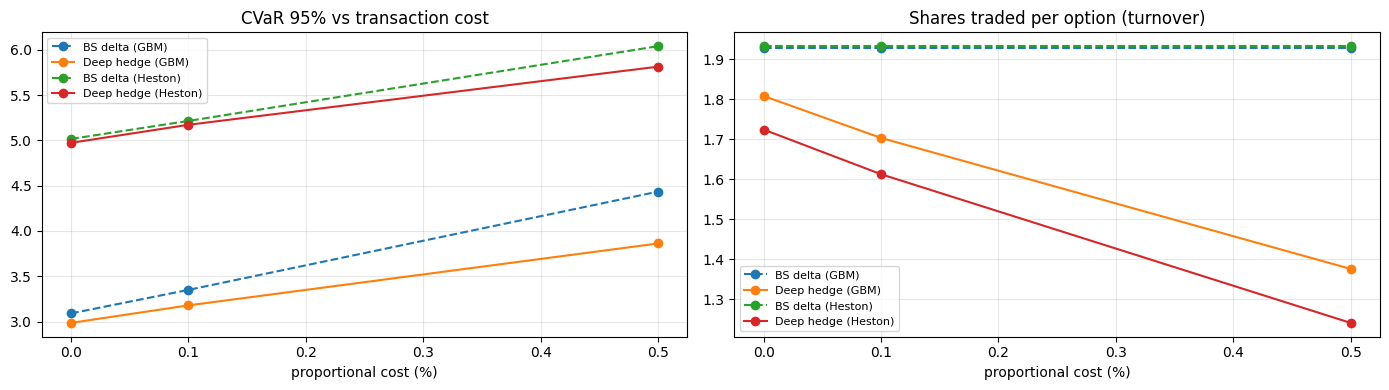

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, model_name in zip(ax, SIMULATORS):
    bs_res, dh_res = eval_store[(model_name, 0.005)]
    lo, hi = np.quantile(np.r_[bs_res["loss"], dh_res["loss"]], [0.001, 0.999])
    bins = np.linspace(lo, hi, 120)
    a.hist(bs_res["loss"], bins=bins, alpha=0.55, density=True, label="BS delta")
    a.hist(dh_res["loss"], bins=bins, alpha=0.55, density=True, label="Deep hedge")
    for res, col in [(bs_res, "C0"), (dh_res, "C1")]:
        L = res["loss"]; a.axvline(L[L >= np.quantile(L, ALPHA)].mean(), color=col, ls="--")
    a.set_title(f"{model_name} market, cost 0.5%: loss distribution (dashed = CVaR 95%)")
    a.set_xlabel("hedging loss"); a.legend()
plt.tight_layout(); plt.savefig("figures/p2_07_loss_distributions.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for model_name in SIMULATORS:
    sub = results.xs(model_name, level="market")
    for strat, ls in [("BS delta", "--"), ("Deep hedge", "-")]:
        s = sub.xs(strat, level="strategy")
        ax[0].plot(np.array(COSTS) * 100, s["CVaR 95%"], ls, marker="o", label=f"{strat} ({model_name})")
        ax[1].plot(np.array(COSTS) * 100, s["mean turnover"], ls, marker="o", label=f"{strat} ({model_name})")
ax[0].set_title("CVaR 95% vs transaction cost"); ax[1].set_title("Shares traded per option (turnover)")
for a in ax: a.set_xlabel("proportional cost (%)"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/p2_08_cost_sweep.png", dpi=150); plt.show()

### What did the network learn? The no-trade band

With costs, the network's new position depends on the position it already holds: the three coloured curves differ only in
the starting position, and each stays pulled toward where it started instead of jumping to the Black–Scholes delta.
In other words, it **trades only partway** toward the ideal hedge, accepting a small hedging error to save costs.
This is a smoothed version of the **no-transaction band** predicted by Whalley & Wilmott (1997); Imaki et al. (2021)
build the band explicitly into the network, which is our Phase III extension (it should make the band sharper and training faster).
Compare with the sanity check: without costs, the position does not depend on the starting point at all.

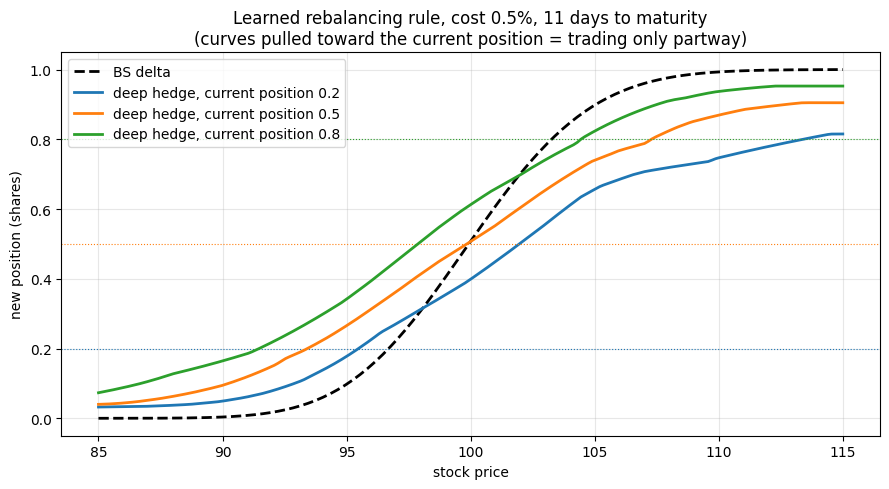

In [ ]:
pol_c = policies[("GBM", 0.005)]
k = 10; tau = (N_STEPS - k) * DT
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(S_grid, bs_delta(S_grid, tau, sigma_gbm), "k--", lw=2, label="BS delta")
for prev, col in [(0.2, "C0"), (0.5, "C1"), (0.8, "C2")]:
    with torch.no_grad():
        x = features(to_t(S_grid), to_t(np.full_like(S_grid, sigma_gbm**2)), tau, to_t(np.full_like(S_grid, prev)))
        out = pol_c(x).cpu().numpy()
    ax.plot(S_grid, out, color=col, lw=2, label=f"deep hedge, current position {prev}")
    ax.axhline(prev, color=col, lw=0.8, ls=":")
ax.set_xlabel("stock price"); ax.set_ylabel("new position (shares)")
ax.set_title(f"Learned rebalancing rule, cost 0.5%, {N_STEPS - k} days to maturity\n(curves pulled toward the current position = trading only partway)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/p2_09_no_trade_band.png", dpi=150); plt.show()

## 10. RQ2 preview: hedging on real SPY history (2019 onward)

Now the honest test: hedgers trained **only on simulated paths** are applied to real SPY 1-month windows from the test period,
which were never used for calibration or training. Each window is rescaled to start at 100, and the option is struck at 100.

* **GBM-trained** hedgers and BS delta use the constant volatility σ calibrated on 2005–2018.
* **Heston-trained** hedgers and the "BS delta with VIX" benchmark use the current volatility from the rescaled VIX each day.

We use **non-overlapping** windows (independent, but few) and **overlapping** windows starting every day
(many more, but correlated) — the second gives more stable estimates.

In [ ]:
def real_windows(data, step):
    P, IV = data["spy"].values, (data["vix"].values**2) * vix_scale
    S, V = [], []
    for i in range(0, len(P) - N_STEPS, step):
        S.append(100 * P[i:i + N_STEPS + 1] / P[i]); V.append(IV[i:i + N_STEPS + 1])
    return np.array(S), np.array(V)

rows = []
for label, step in [("non-overlapping", N_STEPS), ("overlapping", 1)]:
    S_r, V_r = real_windows(test, step)
    V_const = np.full_like(S_r, sigma_gbm**2)
    for c in COSTS:
        cases = [
            ("BS delta (constant vol)", hedge_bs(S_r, V_const, c)),
            ("Deep hedge (GBM-trained)", evaluate(policies[("GBM", c)], S_r, V_const, c)),
            ("BS delta (VIX vol)", hedge_bs(S_r, V_r, c)),
            ("Deep hedge (Heston-trained)", evaluate(policies[("Heston", c)], S_r, V_r, c)),
        ]
        for name, res in cases:
            m = metrics(res, name); m.update({"windows": f"{label} (n={len(S_r)})", "cost": c}); rows.append(m)

real_results = pd.DataFrame(rows).set_index(["windows", "cost", "strategy"])
real_results.to_csv("results/rq2_real_results.csv")
real_results[["mean loss", "std loss", "CVaR 95%", "mean cost", "mean turnover"]]

mean loss  \
windows                cost   strategy                                 
non-overlapping (n=92) 0.0000 BS delta (constant vol)         1.9095   
                              Deep hedge (GBM-trained)        1.9192   
                              BS delta (VIX vol)              1.9262   
                              Deep hedge (Heston-trained)     1.9909   
                       0.0010 BS delta (constant vol)         2.0774   
                              Deep hedge (GBM-trained)        2.0757   
                              BS delta (VIX vol)              2.0978   
                              Deep hedge (Heston-trained)     2.1571   
                       0.0050 BS delta (constant vol)         2.7490   
                              Deep hedge (GBM-trained)        2.5662   
                              BS delta (VIX vol)              2.7841   
                              Deep hedge (Heston-trained)     2.6441   
overlapping (n=1925)   0.0000 BS delta (constant vol)         1.8709   
                              Deep hedge (GBM-trained)        1.8821   
                              BS delta (VIX vol)              1.8442   
                              Deep hedge (Heston-trained)     1.9197   
                       0.0010 BS delta (constant vol)         2.0439   
                              Deep hedge (GBM-trained)        2.0363   
                              BS delta (VIX vol)              2.0201   
                              Deep hedge (Heston-trained)     2.0577   
                       0.0050 BS delta (constant vol)         2.7358   
                              Deep hedge (GBM-trained)        2.5172   
                              BS delta (VIX vol)              2.7236   
                              Deep hedge (Heston-trained)     2.5135   

                                                           std loss  CVaR 95%  \
windows                cost   strategy                                          
non-overlapping (n=92) 0.0000 BS delta (constant vol)        0.8314    4.2150   
                              Deep hedge (GBM-trained)       0.8490    4.2596   
                              BS delta (VIX vol)             1.0066    5.0665   
                              Deep hedge (Heston-trained)    0.9047    4.6448   
                       0.0010 BS delta (constant vol)        0.8489    4.4295   
                              Deep hedge (GBM-trained)       0.8712    4.4848   
                              BS delta (VIX vol)             1.0123    5.2591   
                              Deep hedge (Heston-trained)    1.0224    5.3551   
                       0.0050 BS delta (constant vol)        0.9368    5.3707   
                              Deep hedge (GBM-trained)       0.9314    5.1418   
                              BS delta (VIX vol)             1.0500    6.0295   
                              Deep hedge (Heston-trained)    1.1413    6.2781   
overlapping (n=1925)   0.0000 BS delta (constant vol)        0.9836    4.8536   
                              Deep hedge (GBM-trained)       1.0168    4.9193   
                              BS delta (VIX vol)             0.9997    4.9851   
                              Deep hedge (Heston-trained)    0.9705    4.8359   
                       0.0010 BS delta (constant vol)        1.0066    5.0973   
                              Deep hedge (GBM-trained)       1.0251    5.0955   
                              BS delta (VIX vol)             1.0083    5.1856   
                              Deep hedge (Heston-trained)    0.9676    4.9966   
                       0.0050 BS delta (constant vol)        1.1125    6.1034   
                              Deep hedge (GBM-trained)       1.0397    5.5880   
                              BS delta (VIX vol)             1.0562    6.0061   
                              Deep hedge (Heston-trained)    1.0407    5.6554   

                                                           mean cost  \
windows

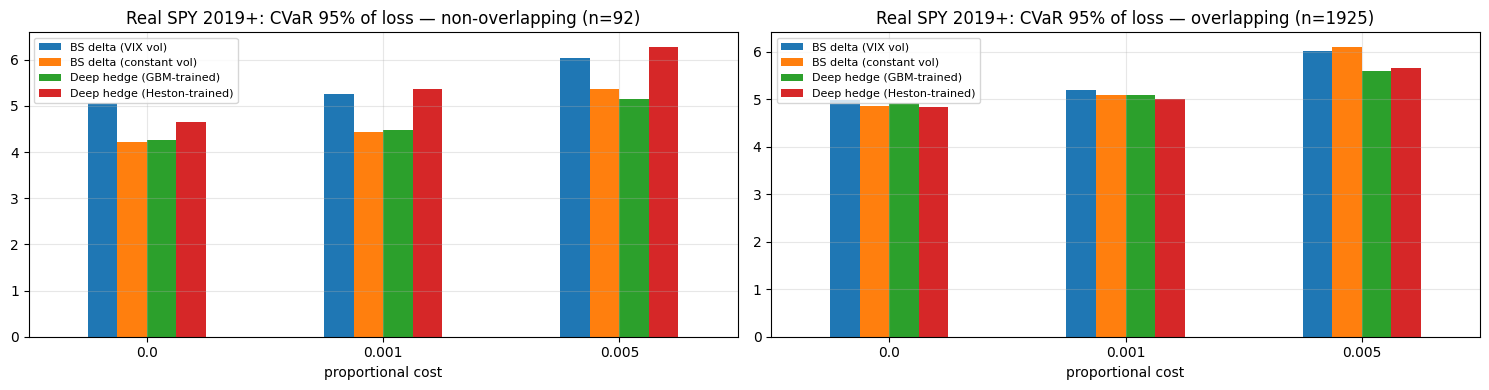

In [ ]:
pivot = real_results["CVaR 95%"].unstack("strategy")
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=False)
for a, (win, sub) in zip(axes, pivot.groupby(level="windows")):
    sub.droplevel("windows").plot(kind="bar", ax=a, rot=0)
    a.set_title(f"Real SPY 2019+: CVaR 95% of loss — {win}"); a.set_xlabel("proportional cost"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/p2_10_real_data_cvar.png", dpi=150); plt.show()

## 11. Results summary (auto-generated from the numbers above)

In [ ]:
def pct(a, b): return 1 - a / b
lines = []
g0 = eval_store[("GBM", 0.0)]
lines.append(f"Sanity check: with no costs, average gap between the learned hedge and BS delta = {gap.mean():.3f} shares.")
for model_name in SIMULATORS:
    for c in COSTS[1:]:
        bs_c = results.loc[(model_name, c, "BS delta"), "CVaR 95%"]
        dh_c = results.loc[(model_name, c, "Deep hedge"), "CVaR 95%"]
        lines.append(f"RQ1 [{model_name}, cost {c:.1%}]: CVaR {dh_c:.3f} (deep) vs {bs_c:.3f} (BS) -> "
                     f"{pct(dh_c, bs_c):+.1%} improvement.")
ov = [w for w in real_results.index.get_level_values("windows").unique() if w.startswith("overlapping")][0]
for c in COSTS[1:]:
    sub = real_results.loc[(ov, c)]["CVaR 95%"]
    lines.append(f"RQ2 preview [real 2019+, cost {c:.1%}, overlapping]: "
                 f"Heston-trained deep hedge {sub['Deep hedge (Heston-trained)']:.3f} vs BS-with-VIX {sub['BS delta (VIX vol)']:.3f}; "
                 f"GBM-trained {sub['Deep hedge (GBM-trained)']:.3f} vs BS-constant {sub['BS delta (constant vol)']:.3f}.")
print("\n".join(lines))
with open("results/summary.txt", "w") as f: f.write("\n".join(lines))

Sanity check: with no costs, average gap between the learned hedge and BS delta = 0.028 shares.
RQ1 [GBM, cost 0.1%]: CVaR 3.178 (deep) vs 3.349 (BS) -> +5.1% improvement.
RQ1 [GBM, cost 0.5%]: CVaR 3.862 (deep) vs 4.434 (BS) -> +12.9% improvement.
RQ1 [Heston, cost 0.1%]: CVaR 5.172 (deep) vs 5.215 (BS) -> +0.8% improvement.
RQ1 [Heston, cost 0.5%]: CVaR 5.814 (deep) vs 6.040 (BS) -> +3.7% improvement.
RQ2 preview [real 2019+, cost 0.1%, overlapping]: Heston-trained deep hedge 4.997 vs BS-with-VIX 5.186; GBM-trained 5.096 vs BS-constant 5.097.
RQ2 preview [real 2019+, cost 0.5%, overlapping]: Heston-trained deep hedge 5.655 vs BS-with-VIX 6.006; GBM-trained 5.588 vs BS-constant 6.103.


# Extended analysis

The first results raise four obvious questions. Each section below answers one of them.

| Question | Section |
|---|---|
| Is the improvement real, or luck from one training run? | 12. Several seeds + bootstrap confidence intervals |
| Black–Scholes ignores costs — is beating it impressive? | 13. Stronger classical benchmarks built for costs |
| Does the hedge work when it matters most? | 14. Crisis stress test (COVID 2020, 2022 sell-off) |
| *Why* does the network win? | 15. Ablation: remove the "current position" input |

Runtime: about 15–20 minutes on a Colab CPU (faster with a GPU), mostly for training extra networks.

In [ ]:
# ---- Extended-analysis configuration ----
N_SEEDS = 5                    # training runs per configuration (seed 0 = the model already trained above)
EXT_COSTS = [0.001, 0.005]     # cost levels studied in the extensions
N_BOOT = 1000                  # bootstrap resamples
BLOCK = N_STEPS                # block length for the real-data block bootstrap (overlapping windows)
rng_boot = np.random.default_rng(7)

def cvar_np(L, a=ALPHA):
    # Average of the worst (1-a) share of losses
    L = np.asarray(L); n = len(L); k = max(1, int(np.ceil((1 - a) * n)))
    return np.partition(L, n - k)[n - k:].mean()

def paired_bootstrap(L_new, L_base, block=1, B=N_BOOT, rng=rng_boot):
    # 95% CI for the CVaR improvement 1 - CVaR(new)/CVaR(base). Same resampled scenarios for both strategies.
    n = len(L_new); out = np.empty(B)
    for b in range(B):
        if block == 1:
            idx = rng.integers(0, n, n)
        else:                                    # moving-block bootstrap keeps neighbouring (correlated) windows together
            starts = rng.integers(0, n - block + 1, int(np.ceil(n / block)))
            idx = (starts[:, None] + np.arange(block)).ravel()[:n]
        out[b] = 1 - cvar_np(L_new[idx]) / cvar_np(L_base[idx])
    return np.quantile(out, [0.025, 0.975])

## 12. Is the improvement real? Several seeds and confidence intervals

Two different kinds of randomness could fake an improvement:

1. **Training randomness.** A neural network starts from random weights and sees random paths, so two training runs give slightly
   different hedges. We therefore train each configuration **5 times with different random seeds** and report the average and spread.
2. **Evaluation randomness.** CVaR is estimated from a finite set of scenarios. A **bootstrap** resamples the test scenarios
   (with replacement) 1,000 times and recomputes the improvement each time; the middle 95% of those values is the
   **95% confidence interval**. If the whole interval is above 0%, the improvement is statistically significant.

Both strategies are always compared on **exactly the same scenarios** (a *paired* comparison), which removes most of the noise.

In [ ]:
seed_policies = {}
for model_name, sim in SIMULATORS.items():
    for c in EXT_COSTS:
        seed_policies[(model_name, c)] = [policies[(model_name, c)]]          # seed 0 = already trained
        for s in range(1, N_SEEDS):
            pol, _ = train_policy(sim, c, seed=SEED + 1000 * s, label=f"{model_name}, c {c:.1%}, seed {s}")
            seed_policies[(model_name, c)].append(pol)

GBM, c 0.1%, seed 1    trained in  25.9s | final CVaR objective 3.182
GBM, c 0.1%, seed 2    trained in  25.9s | final CVaR objective 3.181
GBM, c 0.1%, seed 3    trained in  26.0s | final CVaR objective 3.186
GBM, c 0.1%, seed 4    trained in  25.7s | final CVaR objective 3.188
GBM, c 0.5%, seed 1    trained in  26.0s | final CVaR objective 3.987
GBM, c 0.5%, seed 2    trained in  26.4s | final CVaR objective 3.997
GBM, c 0.5%, seed 3    trained in  26.1s | final CVaR objective 4.002
GBM, c 0.5%, seed 4    trained in  25.6s | final CVaR objective 4.002
Heston, c 0.1%, seed 1 trained in  33.6s | final CVaR objective 5.400
Heston, c 0.1%, seed 2 trained in  34.6s | final CVaR objective 5.403
Heston, c 0.1%, seed 3 trained in  36.0s | final CVaR objective 5.395
Heston, c 0.1%, seed 4 trained in  35.4s | final CVaR objective 5.410
Heston, c 0.5%, seed 1 trained in  35.7s | final CVaR objective 6.388
Heston, c 0.5%, seed 2 trained in  35.5s | final CVaR objective 6.370
Heston, c 0.5%, seed

In [ ]:
rows = []
for model_name, sim in SIMULATORS.items():
    S_ev, V_ev = sim(N_EVAL, seed=2026)
    for c in EXT_COSTS:
        L_bs = hedge_bs(S_ev, V_ev, c)["loss"]
        imps, cvars = [], []
        for i, pol in enumerate(seed_policies[(model_name, c)]):
            L_dh = evaluate(pol, S_ev, V_ev, c)["loss"]
            cvars.append(cvar_np(L_dh)); imps.append(1 - cvar_np(L_dh) / cvar_np(L_bs))
            if i == 0:
                lo, hi = paired_bootstrap(L_dh, L_bs)
        rows.append({"market": model_name, "cost": c, "CVaR BS": cvar_np(L_bs),
                     "CVaR deep (mean of seeds)": np.mean(cvars), "CVaR deep (std across seeds)": np.std(cvars),
                     "improvement seed 0": imps[0], "improvement mean": np.mean(imps), "improvement min seed": np.min(imps),
                     "improvement max seed": np.max(imps), "95% CI low (seed 0)": lo, "95% CI high (seed 0)": hi})

seed_table = pd.DataFrame(rows).set_index(["market", "cost"])
seed_table.to_csv("results/ext_seeds_bootstrap_simulated.csv")
fmt = {c: "{:.1%}".format for c in seed_table.columns if "improvement" in c or "CI" in c}
display(seed_table.style.format(fmt | {c: "{:.3f}" for c in seed_table.columns if c not in fmt}))

In [ ]:
# Same question on real SPY data (2019+, overlapping windows -> moving-block bootstrap)
S_r, V_r = real_windows(test, 1)
V_const = np.full_like(S_r, sigma_gbm**2)
pairs = {"GBM": ("BS delta (constant vol)", V_const), "Heston": ("BS delta (VIX vol)", V_r)}
rows = []
for model_name, (bench, V_in) in pairs.items():
    for c in EXT_COSTS:
        L_bs = hedge_bs(S_r, V_in, c)["loss"]
        imps = [1 - cvar_np(evaluate(p, S_r, V_in, c)["loss"]) / cvar_np(L_bs) for p in seed_policies[(model_name, c)]]
        lo, hi = paired_bootstrap(evaluate(seed_policies[(model_name, c)][0], S_r, V_in, c)["loss"], L_bs, block=BLOCK)
        rows.append({"hedger": f"{model_name}-trained vs {bench}", "cost": c, "improvement seed 0": imps[0],
                     "improvement mean of seeds": np.mean(imps),
                     "min seed": np.min(imps), "max seed": np.max(imps), "95% CI low": lo, "95% CI high": hi})
real_seed_table = pd.DataFrame(rows).set_index(["hedger", "cost"])
real_seed_table.to_csv("results/ext_seeds_bootstrap_real.csv")
display(real_seed_table.style.format("{:.1%}"))

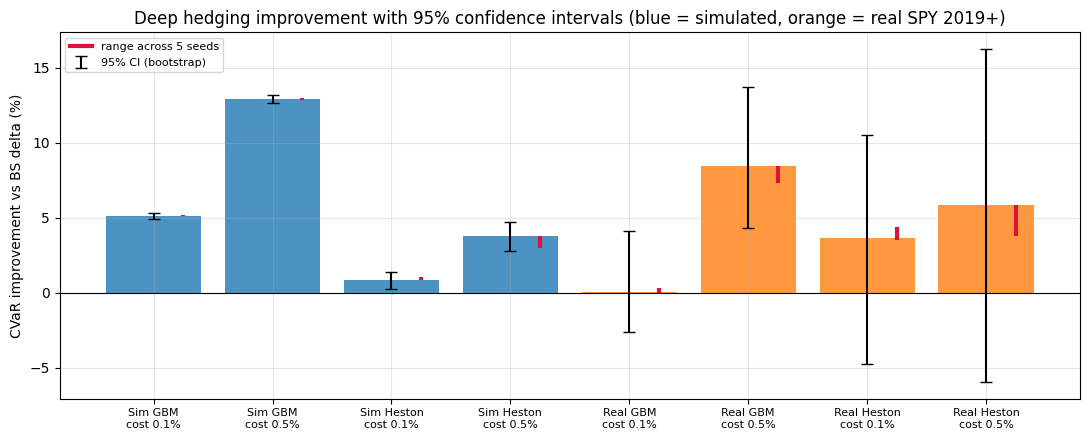

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
labels, pts, los, his, spreads = [], [], [], [], []
for (m, c), r in seed_table.iterrows():
    labels.append(f"Sim {m}\ncost {c:.1%}"); pts.append(r["improvement seed 0"])
    los.append(r["95% CI low (seed 0)"]); his.append(r["95% CI high (seed 0)"])
    spreads.append((r["improvement min seed"], r["improvement max seed"]))
for (h, c), r in real_seed_table.iterrows():
    labels.append(f"Real {h.split('-')[0]}\ncost {c:.1%}"); pts.append(r["improvement seed 0"])
    los.append(r["95% CI low"]); his.append(r["95% CI high"]); spreads.append((r["min seed"], r["max seed"]))
x = np.arange(len(labels)); pts, los, his = map(np.array, (pts, los, his))
ax.bar(x, pts * 100, color=["C0"] * len(seed_table) + ["C1"] * len(real_seed_table), alpha=0.8)
ax.errorbar(x, pts * 100, yerr=[np.maximum(pts - los, 0) * 100, np.maximum(his - pts, 0) * 100],
            fmt="none", ecolor="k", capsize=4, label="95% CI (bootstrap)")
for xpos, (lo_s, hi_s) in zip(x, spreads):          # (do not reuse model parameter names such as xi)
    ax.plot([xpos + 0.25] * 2, [lo_s * 100, hi_s * 100], color="crimson", lw=3, solid_capstyle="butt")
ax.plot([], [], color="crimson", lw=3, label=f"range across {N_SEEDS} seeds")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.legend(fontsize=8)
ax.set_ylabel("CVaR improvement vs BS delta (%)")
ax.set_title("Deep hedging improvement with 95% confidence intervals (blue = simulated, orange = real SPY 2019+)")
plt.tight_layout(); plt.savefig("figures/p2_11_confidence_intervals.png", dpi=150); plt.show()

**How to read this.** A bar whose error bar stays entirely above 0 is a statistically significant improvement.
The real-data intervals are wider than the simulated ones because there are far fewer real scenarios, and neighbouring
windows overlap, so the *block* bootstrap is used (it resamples chunks of 21 consecutive windows to respect that overlap).
The seed columns show whether a different training run would have changed the conclusion.

## 13. Stronger benchmarks: classical hedges designed for transaction costs

Beating Black–Scholes delta under costs is expected, since it ignores costs. Finance theory has two classic answers built for costs:

* **Leland (1985) — cost-adjusted volatility.** Hedge with the Black–Scholes delta, but computed with an inflated volatility
  $\sigma_L = \sigma\sqrt{1 + Le}$, where the *Leland number* $Le = \sqrt{2/\pi}\;\dfrac{2c}{\sigma\sqrt{\Delta t}}$.
  A higher volatility makes the delta curve flatter, so the hedge changes less often and trades less.
* **Whalley & Wilmott (1997) — no-trade band.** Keep the Black–Scholes delta as the target, but only trade when the current
  position leaves a band around it, and then only up to the edge of the band. The half-width of the band is
  $H = \left(\dfrac{3\,c\,S\,\Gamma^2}{2\gamma}\right)^{1/3}$, where $\Gamma$ (gamma) is how fast delta changes with the price and
  $\gamma$ is the hedger's risk aversion. We pick $\gamma$ to give the lowest CVaR on separate simulated paths, so this benchmark
  is tuned just like the network.

If the network beats **these**, it is doing more than rediscovering textbook cost-aware hedging.

In [ ]:
def bs_gamma(S, tau, sigma):
    tau = np.maximum(tau, 1e-10)
    d1 = (np.log(S / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.pdf(d1) / (S * sigma * np.sqrt(tau))

def _run_rule(S, rule, c):
    n = S.shape[0]; pos = np.zeros(n); gains = np.zeros(n); cost = np.zeros(n); turnover = np.zeros(n)
    for k in range(N_STEPS):
        new = rule(k, pos)
        trade = np.abs(new - pos); cost += c * S[:, k] * trade; turnover += trade
        gains += new * (S[:, k + 1] - S[:, k]); pos = new
    return {"loss": np.maximum(S[:, -1] - K, 0) - gains + cost, "cost": cost, "turnover": turnover}

def hedge_leland(S, V, c):
    def rule(k, pos):
        sig = np.sqrt(V[:, k]); le = np.sqrt(2 / np.pi) * 2 * c / (sig * np.sqrt(DT))
        return bs_delta(S[:, k], (N_STEPS - k) * DT, sig * np.sqrt(1 + le))
    return _run_rule(S, rule, c)

def hedge_ww(S, V, c, gamma_ra):
    def rule(k, pos):
        tau, sig = (N_STEPS - k) * DT, np.sqrt(V[:, k])
        target = bs_delta(S[:, k], tau, sig)
        if c == 0:
            return target
        H = (1.5 * c * S[:, k] * bs_gamma(S[:, k], tau, sig)**2 / gamma_ra) ** (1 / 3)
        return np.clip(pos, target - H, target + H)        # move only to the nearest edge of the band
    return _run_rule(S, rule, c)

# Tune the Whalley-Wilmott risk aversion on separate simulated paths (not the evaluation paths)
GAMMA_GRID = np.logspace(-2, 5, 29)
ww_gamma = {}
for model_name, sim in SIMULATORS.items():
    S_tu, V_tu = sim(50_000, seed=77)
    for c in EXT_COSTS:
        scores = [cvar_np(hedge_ww(S_tu, V_tu, c, g)["loss"]) for g in GAMMA_GRID]
        ww_gamma[(model_name, c)] = GAMMA_GRID[int(np.argmin(scores))]
print("Tuned Whalley-Wilmott risk aversion:", {k: round(float(v), 3) for k, v in ww_gamma.items()})
edge = [k for k, v in ww_gamma.items() if v in (GAMMA_GRID[0], GAMMA_GRID[-1])]
if edge: print("Note: optimum at the edge of the grid for", edge,
               "- a very large risk aversion means the band shrinks to (almost) plain BS delta: at low cost, the band barely helps.")

Tuned Whalley-Wilmott risk aversion: {('GBM', 0.001): 100.0, ('GBM', 0.005): 10.0, ('Heston', 0.001): 31.623, ('Heston', 0.005): 3.162}


In [ ]:
def all_strategies(S, V, c, model_name):
    return {"BS delta": hedge_bs(S, V, c),
            "Leland": hedge_leland(S, V, c),
            "Whalley-Wilmott": hedge_ww(S, V, c, ww_gamma[(model_name, c)]),
            "Deep hedge": evaluate(policies[(model_name, c)], S, V, c)}

rows = []
for model_name, sim in SIMULATORS.items():
    S_ev, V_ev = sim(N_EVAL, seed=2026)
    for c in EXT_COSTS:
        res = all_strategies(S_ev, V_ev, c, model_name)
        for name, r in res.items():
            m = metrics(r, name); m.update({"data": f"simulated {model_name}", "cost": c}); rows.append(m)
        lo, hi = paired_bootstrap(res["Deep hedge"]["loss"], res["Whalley-Wilmott"]["loss"])
        rows[-1]["CI vs best classical"] = f"vs WW: [{lo:.1%}, {hi:.1%}]"
for model_name, (bench, V_in) in pairs.items():
    for c in EXT_COSTS:
        res = all_strategies(S_r, V_in, c, model_name)
        for name, r in res.items():
            m = metrics(r, name); m.update({"data": f"real SPY 2019+ ({model_name} setup)", "cost": c}); rows.append(m)
        lo, hi = paired_bootstrap(res["Deep hedge"]["loss"], res["Whalley-Wilmott"]["loss"], block=BLOCK)
        rows[-1]["CI vs best classical"] = f"vs WW: [{lo:.1%}, {hi:.1%}]"

bench_table = pd.DataFrame(rows).set_index(["data", "cost", "strategy"])
bench_table.to_csv("results/ext_benchmarks.csv")
bench_table[["mean loss", "CVaR 95%", "mean cost", "mean turnover", "CI vs best classical"]]

mean loss  CVaR 95%  \
data                          cost   strategy                               
simulated GBM                 0.0010 BS delta            2.3428    3.3492   
                                     Leland              2.3385    3.2872   
                                     Whalley-Wilmott     2.3100    3.3124   
                                     Deep hedge          2.3205    3.1782   
                              0.0050 BS delta            3.1140    4.4339   
                                     Leland              3.0273    4.0342   
                                     Whalley-Wilmott     2.7278    4.0794   
                                     Deep hedge          2.8381    3.8616   
simulated Heston              0.0010 BS delta            2.1203    5.2145   
                                     Leland              2.1152    5.2106   
                                     Whalley-Wilmott     2.0735    5.1986   
                                     Deep hedge          2.0887    5.1718   
                              0.0050 BS delta            2.8939    6.0397   
                                     Leland              2.7967    5.9587   
                                     Whalley-Wilmott     2.4305    5.8097   
                                     Deep hedge          2.5508    5.8136   
real SPY 2019+ (GBM setup)    0.0010 BS delta            2.0439    5.0973   
                                     Leland              2.0436    5.0968   
                                     Whalley-Wilmott     2.0140    5.0004   
                                     Deep hedge          2.0363    5.0955   
                              0.0050 BS delta            2.7358    6.1034   
                                     Leland              2.6749    6.0197   
                                     Whalley-Wilmott     2.4246    5.5099   
                                     Deep hedge          2.5172    5.5880   
real SPY 2019+ (Heston setup) 0.0010 BS delta            2.0201    5.1856   
                                     Leland              2.0208    5.1982   
                                     Whalley-Wilmott     1.9786    5.0540   
                                     Deep hedge          2.0577    4.9966   
                              0.0050 BS delta            2.7236    6.0061   
                                     Leland              2.6595    6.0106   
                                     Whalley-Wilmott     2.3572    5.5498   
                                     Deep hedge          2.5135    5.6554   

                                                      mean cost  \
data                          cost   strategy                     
simulated GBM                 0.0010 BS delta            0.1928   
                                     Leland              0.1885   
                                     Whalley-Wilmott     0.1604   
                                     Deep hedge          0.1703   
                              0.0050 BS delta            0.9640   
                                     Leland              0.8771   
                                     Whalley-Wilmott     0.5784   
                                     Deep hedge          0.6881   
simulated Heston              0.0010 BS delta            0.1934   
                                     Leland              0.1882   
                                     Whalley-Wilmott     0.1459   
                                     Deep hedge          0.1616   
                              0.0050 BS delta            0.9670   
                                     Leland              0.8697   
                                     Whalley-Wilmott     0.5010   
                                     Deep hedge          0.6220   
real SPY 2019+ (GBM setup)    0.0010 BS delta            0.1730   
                                     Leland              0.1693   
                                     Whalley-Wilmott     0.1435   
                            

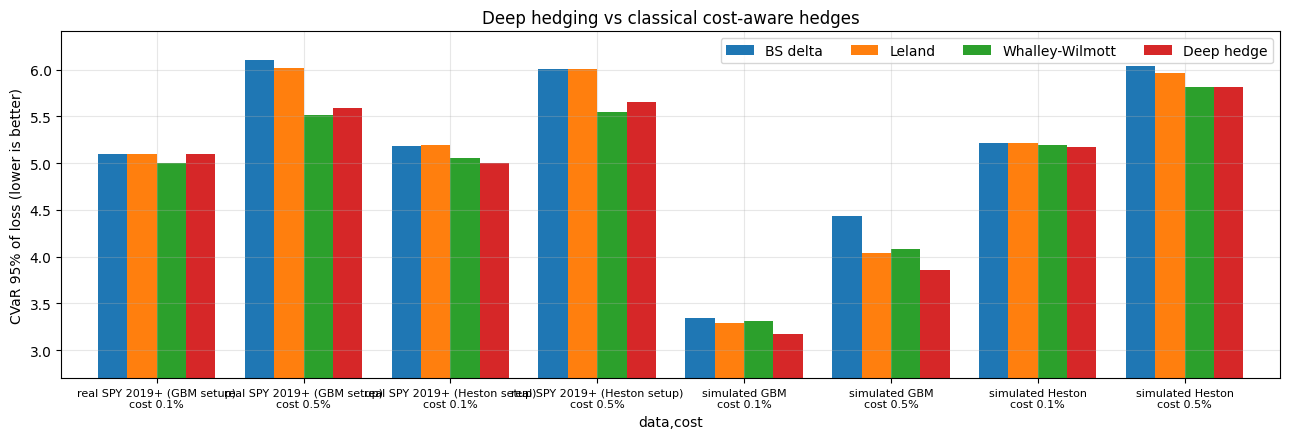

In [ ]:
cv = bench_table["CVaR 95%"].unstack("strategy")[["BS delta", "Leland", "Whalley-Wilmott", "Deep hedge"]]
fig, ax = plt.subplots(figsize=(13, 4.5))
cv.plot(kind="bar", ax=ax, rot=0, width=0.8)
ax.set_xticklabels([f"{d}\ncost {c:.1%}" for d, c in cv.index], fontsize=8)
ax.set_ylabel("CVaR 95% of loss (lower is better)"); ax.set_title("Deep hedging vs classical cost-aware hedges")
ax.set_ylim(cv.values.min() * 0.85, cv.values.max() * 1.05); ax.legend(ncol=4)
plt.tight_layout(); plt.savefig("figures/p2_12_benchmarks.png", dpi=150); plt.show()

**How to read this.** Leland and Whalley–Wilmott should already beat plain Black–Scholes under costs, because they were designed for it.
The key comparison is **Deep hedge vs Whalley–Wilmott**, the strongest classical method; the last column gives the 95% confidence interval
of that improvement. Whatever the outcome, it is informative: a clear win means the network learned something beyond the textbook band
(for example, adapting to the CVaR objective and to time-to-maturity); a tie means the network independently rediscovered the
optimal classical strategy, which is itself strong evidence that it learned correctly.

## 14. Crisis stress test: COVID crash (2020) and the 2022 sell-off

Hedging is easy in calm markets; banks lose money in crises. We isolate real 1-month windows that **start** inside two stress periods:

* **COVID crash:** windows starting 1 Feb – 30 Apr 2020 (the S&P 500 fell about a third in a month, VIX above 80).
* **2022 sell-off:** windows starting 1 Jan – 31 Oct 2022 (rate hikes, a long falling market).

Windows overlap, so these are illustrative stress results rather than large independent samples.

In [ ]:
starts = test.index[:len(S_r)]                    # start date of each overlapping real window
periods = {"COVID crash (Feb-Apr 2020)": ("2020-02-01", "2020-04-30"),
           "2022 sell-off (Jan-Oct 2022)": ("2022-01-01", "2022-10-31"),
           "All 2019+ windows": (str(starts.min().date()), str(starts.max().date()))}
rows = []
for model_name, (bench, V_in) in pairs.items():
    for c in EXT_COSTS:
        res = all_strategies(S_r, V_in, c, model_name)
        for pname, (a, b) in periods.items():
            mask = (starts >= a) & (starts <= b)
            for name, r in res.items():
                rows.append({"period": pname, "setup": model_name, "cost": c, "strategy": name, "windows": int(mask.sum()),
                             "mean loss": r["loss"][mask].mean(), "CVaR 95%": cvar_np(r["loss"][mask]),
                             "worst loss": r["loss"][mask].max()})
crisis = pd.DataFrame(rows).set_index(["period", "setup", "cost", "strategy"])
crisis.to_csv("results/ext_crisis.csv")
crisis.xs(0.005, level="cost")

windows  mean loss  \
period                       setup  strategy                              
COVID crash (Feb-Apr 2020)   GBM    BS delta              62     5.6597   
                                    Leland                62     5.8274   
                                    Whalley-Wilmott       62     5.3271   
                                    Deep hedge            62     5.4970   
2022 sell-off (Jan-Oct 2022) GBM    BS delta             209     3.8875   
                                    Leland               209     3.8560   
                                    Whalley-Wilmott      209     3.4278   
                                    Deep hedge           209     3.6660   
All 2019+ windows            GBM    BS delta            1925     2.7358   
                                    Leland              1925     2.6749   
                                    Whalley-Wilmott     1925     2.4246   
                                    Deep hedge          1925     2.5172   
COVID crash (Feb-Apr 2020)   Heston BS delta              62     5.9643   
                                    Leland                62     6.0957   
                                    Whalley-Wilmott       62     5.4955   
                                    Deep hedge            62     5.5019   
2022 sell-off (Jan-Oct 2022) Heston BS delta             209     3.8172   
                                    Leland               209     3.7832   
                                    Whalley-Wilmott      209     3.3198   
                                    Deep hedge           209     3.4409   
All 2019+ windows            Heston BS delta            1925     2.7236   
                                    Leland              1925     2.6595   
                                    Whalley-Wilmott     1925     2.3572   
                                    Deep hedge          1925     2.5135   

                                                     CVaR 95%  worst loss  
period                       setup  strategy                               
COVID crash (Feb-Apr 2020)   GBM    BS delta          13.4684     18.5518  
                                    Leland            13.0883     16.9642  
                                    Whalley-Wilmott   12.1396     16.9638  
                                    Deep hedge        10.6089     13.5458  
2022 sell-off (Jan-Oct 2022) GBM    BS delta           5.7328      6.1960  
                                    Leland             5.2797      5.7333  
                                    Whalley-Wilmott    5.3974      6.4676  
                                    Deep hedge         5.1837      6.1239  
All 2019+ windows            GBM    BS delta           6.1034     18.5518  
                                    Leland             6.0197     16.9642  
                                    Whalley-Wilmott    5.5099     16.9638  
                                    Deep hedge         5.5880     13.5458  
COVID crash (Feb-Apr 2020)   Heston BS delta          10.8504     11.3236  
                                    Leland            10.7010     10.8504  
                                    Whalley-Wilmott    9.7134      9.8468  
                                    Deep hedge        11.1941     14.7275  
2022 sell-off (Jan-Oct 2022) Heston BS delta           5.2382      5.8417  
                                    Leland             5.0671      5.5710  
                                    Whalley-Wilmott    5.4020      6.3974  
                                    Deep hedge         5.3401      6.1416  
All 2019+ windows            Heston BS delta           6.0061     11.3236  
                                    Leland             6.0106     10.8504  
                                    Whalley-Wilmott    5.5498      9.8468  
                                    Deep hedge         5.6554     14.7275

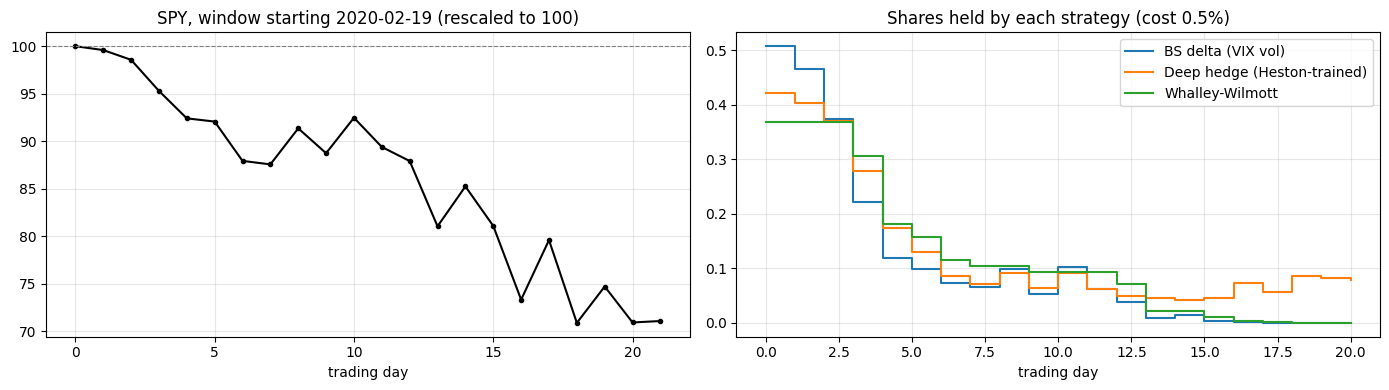

In [ ]:
# One concrete crash window: what each strategy actually did
crash_day = starts[starts >= "2020-02-19"][0]           # S&P 500 peak just before the COVID crash
i = int(np.where(starts == crash_day)[0][0]); c = 0.005
S1, V1 = S_r[i:i + 1], V_r[i:i + 1]
paths = {"BS delta (VIX vol)": hedge_bs(S1, V1, c)["deltas"][0],
         "Deep hedge (Heston-trained)": evaluate(policies[("Heston", c)], S1, V1, c)["deltas"][0]}
ww_pos, pos = [], np.zeros(1)
for k in range(N_STEPS):
    tau, sig = (N_STEPS - k) * DT, np.sqrt(V1[:, k]); tgt = bs_delta(S1[:, k], tau, sig)
    H = (1.5 * c * S1[:, k] * bs_gamma(S1[:, k], tau, sig)**2 / ww_gamma[("Heston", c)]) ** (1 / 3)
    pos = np.clip(pos, tgt - H, tgt + H); ww_pos.append(pos[0])
paths["Whalley-Wilmott"] = np.array(ww_pos)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(S1[0], "k-o", ms=3); ax[0].axhline(K, color="gray", ls="--", lw=0.8)
ax[0].set_title(f"SPY, window starting {crash_day.date()} (rescaled to 100)"); ax[0].set_xlabel("trading day")
for name, p in paths.items(): ax[1].step(range(N_STEPS), p, where="post", label=name)
ax[1].set_title("Shares held by each strategy (cost 0.5%)"); ax[1].set_xlabel("trading day"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/p2_13_covid_window.png", dpi=150); plt.show()

**How to read this.** The table compares strategies inside each stress period; the figure shows one real crash month day by day.
In a crash the call falls far out of the money, so every sensible hedge sells its shares; the question is how quickly, and how much
it pays in costs while doing so. Compare the "All 2019+" rows with the crisis rows to see whether the advantage holds, grows, or
shrinks under stress.

## 15. Ablation: why does the network win?

An **ablation** removes one part of a model to see how much that part matters. Our claim is that the network wins under costs because
it knows **how many shares it already holds**, which lets it decide *not* to trade. We test this by retraining the network with
that input set to zero ("no memory"), keeping everything else identical, and measure how much of the advantage — in tail risk
(CVaR) and in trading costs — disappears.

In [ ]:
class NoMemoryPolicy(HedgePolicy):
    def forward(self, x):
        x = x.clone(); x[:, 3] = 0.0                      # hide the current position
        return super().forward(x)

ablation_rows = []
for model_name, sim in SIMULATORS.items():
    c = 0.005
    nomem, _ = train_policy(sim, c, policy_cls=NoMemoryPolicy, label=f"{model_name}, c 0.5%, no memory")
    S_ev, V_ev = sim(N_EVAL, seed=2026)
    for name, r in [("BS delta", hedge_bs(S_ev, V_ev, c)),
                    ("Deep hedge, no memory", evaluate(nomem, S_ev, V_ev, c)),
                    ("Deep hedge, full", evaluate(policies[(model_name, c)], S_ev, V_ev, c))]:
        m = metrics(r, name); m.update({"market": model_name}); ablation_rows.append(m)
ablation = pd.DataFrame(ablation_rows).set_index(["market", "strategy"])
ablation.to_csv("results/ext_ablation.csv")
ablation[["mean loss", "CVaR 95%", "mean cost", "mean turnover"]]

GBM, c 0.5%, no memory trained in  28.6s | final CVaR objective 4.055
Heston, c 0.5%, no memory trained in  36.4s | final CVaR objective 6.491


mean loss  CVaR 95%  mean cost  mean turnover
market strategy                                                            
GBM    BS delta                  3.1140    4.4339     0.9640         1.9284
       Deep hedge, no memory     2.9381    3.9062     0.7878         1.5760
       Deep hedge, full          2.8381    3.8616     0.6881         1.3763
Heston BS delta                  2.8939    6.0397     0.9670         1.9328
       Deep hedge, no memory     2.6022    5.9550     0.6728         1.3438
       Deep hedge, full          2.5508    5.8136     0.6220         1.2414

**How to read this.** Without memory the network can still learn a "smoother" delta that trades a little less (similar in spirit to Leland),
so it may beat Black–Scholes somewhat. The gap between "no memory" and "full" is the part of the advantage that comes specifically from
knowing the current position, i.e. from the no-trade behaviour.

## 16. Extended results summary (auto-generated)

In [ ]:
def verdict(lo, hi):
    if lo > 0: return "significantly better"
    if hi < 0: return "significantly worse"
    return "not significantly different"
lines = []
for (m, c), r in seed_table.iterrows():
    sig = verdict(r["95% CI low (seed 0)"], r["95% CI high (seed 0)"])
    lines.append(f"[Sim {m}, cost {c:.1%}] improvement vs BS: mean {r['improvement mean']:+.1%} over {N_SEEDS} seeds "
                 f"(range {r['improvement min seed']:+.1%} to {r['improvement max seed']:+.1%}); "
                 f"95% CI [{r['95% CI low (seed 0)']:+.1%}, {r['95% CI high (seed 0)']:+.1%}] -> {sig}.")
for (h, c), r in real_seed_table.iterrows():
    sig = verdict(r["95% CI low"], r["95% CI high"])
    lines.append(f"[Real 2019+, {h}, cost {c:.1%}] mean {r['improvement mean of seeds']:+.1%}; "
                 f"95% CI [{r['95% CI low']:+.1%}, {r['95% CI high']:+.1%}] -> {sig}.")
for (d, c), grp in bench_table.groupby(level=["data", "cost"]):
    g = grp.droplevel(["data", "cost"])["CVaR 95%"]
    best_classical = g.drop("Deep hedge").idxmin()
    lines.append(f"[Benchmarks, {d}, cost {c:.1%}] best classical = {best_classical} ({g[best_classical]:.3f}); "
                 f"deep hedge {g['Deep hedge']:.3f} ({1 - g['Deep hedge'] / g[best_classical]:+.1%}).")
for m in SIMULATORS:
    a = ablation.xs(m)["CVaR 95%"]
    adv = a["BS delta"] - a["Deep hedge, full"]
    share = (a["Deep hedge, no memory"] - a["Deep hedge, full"]) / adv if adv > 0 else np.nan
    lines.append(f"[Ablation, {m}, cost 0.5%] CVaR: BS {a['BS delta']:.3f}, no memory {a['Deep hedge, no memory']:.3f}, "
                 f"full {a['Deep hedge, full']:.3f} -> " + (f"about {share:.0%} of the CVaR advantage comes from knowing the current position; " if adv > 0 else "no CVaR advantage over BS to attribute; ") +
                 f"trading costs: BS {ablation.xs(m)['mean cost']['BS delta']:.3f}, no memory {ablation.xs(m)['mean cost']['Deep hedge, no memory']:.3f}, "
                 f"full {ablation.xs(m)['mean cost']['Deep hedge, full']:.3f}.")
print("\n".join(lines))
with open("results/ext_summary.txt", "w") as f: f.write("\n".join(lines))

[Sim GBM, cost 0.1%] improvement vs BS: mean +5.1% over 5 seeds (range +5.1% to +5.1%); 95% CI [+4.9%, +5.3%] -> significantly better.
[Sim GBM, cost 0.5%] improvement vs BS: mean +12.9% over 5 seeds (range +12.9% to +13.0%); 95% CI [+12.7%, +13.1%] -> significantly better.
[Sim Heston, cost 0.1%] improvement vs BS: mean +0.9% over 5 seeds (range +0.8% to +1.1%); 95% CI [+0.2%, +1.4%] -> significantly better.
[Sim Heston, cost 0.5%] improvement vs BS: mean +3.4% over 5 seeds (range +2.9% to +3.7%); 95% CI [+2.8%, +4.7%] -> significantly better.
[Real 2019+, GBM-trained vs BS delta (constant vol), cost 0.1%] mean +0.1%; 95% CI [-2.6%, +4.1%] -> not significantly different.
[Real 2019+, GBM-trained vs BS delta (constant vol), cost 0.5%] mean +7.8%; 95% CI [+4.3%, +13.7%] -> significantly better.
[Real 2019+, Heston-trained vs BS delta (VIX vol), cost 0.1%] mean +3.9%; 95% CI [-4.8%, +10.5%] -> not significantly different.
[Real 2019+, Heston-trained vs BS delta (VIX vol), cost 0.5%] mean

In [ ]:
  !zip -r phase2_outputs.zip figures results
  from google.colab import files
  files.download("phase2_outputs.zip")

  adding: figures/ (stored 0%)
  adding: figures/p2_02_leverage_effect.png (deflated 11%)
  adding: figures/p2_03_vol_premium_and_regimes.png (deflated 7%)
  adding: figures/p2_01_volatility_clustering.png (deflated 20%)
  adding: figures/p2_12_benchmarks.png (deflated 21%)
  adding: figures/p2_09_no_trade_band.png (deflated 8%)
  adding: figures/p2_06_sanity_check.png (deflated 10%)
  adding: figures/p2_04_heston_paths.png (deflated 1%)
  adding: figures/p2_05_training_curves.png (deflated 9%)
  adding: figures/p2_13_covid_window.png (deflated 15%)
  adding: figures/p2_08_cost_sweep.png (deflated 9%)
  adding: figures/p2_10_real_data_cvar.png (deflated 15%)
  adding: figures/p2_11_confidence_intervals.png (deflated 18%)
  adding: figures/p2_07_loss_distributions.png (deflated 15%)
  adding: results/ (stored 0%)
  adding: results/policy_GBM_0.001.pt (deflated 24%)
  adding: results/rq1_simulated_results.csv (deflated 51%)
  adding: results/policy_Heston_0.0.pt (deflated 24%)
  adding: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Limitations and next steps (Phase III)

**Remaining limitations**
* Heston is calibrated with a VIX-based variance proxy rather than to real option prices.
  *Planned fix:* real SPX option data from Databento (OPRA), used for calibration and for real premium-based P&L.
* Real-data results rely on the VIX as the volatility input, and the real test set is small and overlapping
  (handled with a block bootstrap, but intervals remain wide).
* Training budget is modest (`ITERS = 800`); interest rates are ignored over the 1-month horizon.

**Phase III plan**
1. **Real option data:** SPX options from Databento — calibrate Heston to the implied-volatility surface; hedge real contracts with real premiums.
2. **No-transaction band network** (Imaki et al., 2021) — compare with the plain network and the Whalley–Wilmott band.
3. **Reinforcement learning formulation:** hedging as an MDP solved with an actor–critic method (Buehler, Murray & Wood, 2022).
4. **Data-driven simulator:** train on block-bootstrapped real 2005–2018 history, then test on 2019+.
5. **American put** extension, where early exercise matters.

**References added in the extended analysis:** Leland, H. (1985), *Option pricing and replication with transaction costs*, Journal of Finance;
Whalley, A. E. & Wilmott, P. (1997), Mathematical Finance; Efron, B. & Tibshirani, R. (1993), *An Introduction to the Bootstrap*;
Künsch, H. (1989), *The jackknife and the bootstrap for general stationary observations*, Annals of Statistics (block bootstrap).